In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load OpenPose model (COCO)
proto_file = "C:/Models/pose_deploy_linevec.prototxt"
weights_file = "C:/Models/pose_iter_440000.caffemodel"
net = cv2.dnn.readNetFromCaffe(proto_file, weights_file)


In [3]:
import os
assert os.path.isfile(proto_file), f"Proto file not found at {proto_file}"
assert os.path.isfile(weights_file), f"Weights file not found at {weights_file}"


In [4]:
# Define COCO body parts and their connections
POSE_PAIRS = [
    (1,2), (1,5), (2,3), (3,4), (5,6), (6,7),
    (1,8), (8,9), (9,10), (1,11), (11,12), (12,13),
    (1,0), (0,14), (14,16), (0,15), (15,17)
]

In [5]:
# Function to generate skeleton overlay
def draw_skeleton(img, points, threshold=0.1):
    for i in range(len(points)):
        if points[i]:
            cv2.circle(img, points[i], 5, (0,255,0), -1)
    for pair in POSE_PAIRS:
        partA, partB = pair
        if points[partA] and points[partB]:
            cv2.line(img, points[partA], points[partB], (0,0,255), 2)
    return img

In [6]:
# Function to create heatmap for a single keypoint
def generate_heatmap(img, points, threshold=0.1):
    heatmaps = []
    for (x, y) in points:
        hm = np.zeros_like(img, dtype=np.float32)
        if x is not None and y is not None:
            cv2.circle(hm, (x, y), 7, (1), thickness=-1)  # Add gaussian blur to smooth the heatmap
            hm = cv2.GaussianBlur(hm, (15, 15), 0)
        heatmaps.append(hm)
    return np.stack(heatmaps, axis=-1)  # Stack into a tensor (H, W, 18)

In [7]:
# Function to extract keypoints from image
def extract_keypoints(img):
    h, w = img.shape[:2]
    inp = cv2.dnn.blobFromImage(img, 1.0 / 255, (w, h), (0,0,0), swapRB=False, crop=False)
    net.setInput(inp)
    out = net.forward()

    points = []
    for i in range(18):  # COCO has 18 keypoints
        prob_map = out[0, i, :, :]
        _, conf, _, point = cv2.minMaxLoc(prob_map)
        x = (w * point[0]) / prob_map.shape[1]
        y = (h * point[1]) / prob_map.shape[0]
        if conf > 0.1:  # Threshold for keypoint confidence
            points.append((int(x), int(y)))
        else:
            points.append(None)
    return points


In [8]:
# Path to dataset and classes
data_dir = "C:/pose_estimation"  # Adjust the dataset path
classes = ['drive', 'legglance-flick', 'pullshot', 'sweep']

In [9]:
# Prepare for saving output images
output_dir = 'processed_images'
os.makedirs(output_dir, exist_ok=True)

In [10]:
def generate_heatmap(img, points, radius=7, blur_ksize=(15,15)):
    """
    - img: original BGR image
    - points: list of (x,y) or None
    Returns a single H×W heatmap where all joint heatmaps are summed.
    """
    h, w = img.shape[:2]
    all_hms = []

    for pt in points:
        # single‑channel blank canvas
        hm = np.zeros((h, w), dtype=np.float32)
        if pt is not None:
            x, y = pt
            cv2.circle(hm, (x, y), radius, 1, thickness=-1)
            hm = cv2.GaussianBlur(hm, blur_ksize, 0)
        all_hms.append(hm)

    # sum (or you could take max) across all joint heatmaps
    summed = np.sum(all_hms, axis=0)
    # normalize to [0,255]
    if summed.max() > 0:
        summed = summed / summed.max()
    return (summed * 255).astype(np.uint8)

# In your processing loop, replace the old heatmap saving block with this:

for cls in classes:
    class_dir = os.path.join(data_dir, cls)
    out_cls_dir = os.path.join(output_dir, cls)
    os.makedirs(out_cls_dir, exist_ok=True)

    for img_file in os.listdir(class_dir):
        if not img_file.lower().endswith(('.png','.jpg','.jpeg')):
            continue

        img_path = os.path.join(class_dir, img_file)
        img = cv2.imread(img_path)

        # 1) Skeleton
        points = extract_keypoints(img)
        skeleton = draw_skeleton(img.copy(), points)
        cv2.imwrite(
            os.path.join(out_cls_dir, f"{os.path.splitext(img_file)[0]}_skeleton.png"),
            skeleton
        )

        # 2) Combined Heatmap
        heatmap = generate_heatmap(img, points)
        cv2.imwrite(
            os.path.join(out_cls_dir, f"{os.path.splitext(img_file)[0]}_heatmap.png"),
            heatmap
        )

        print(f"Processed {cls}/{img_file}")

Processed drive/drives1.png
Processed drive/drives10.png
Processed drive/drives100.png
Processed drive/drives101.png
Processed drive/drives102.png
Processed drive/drives103.png
Processed drive/drives104.png
Processed drive/drives105.png
Processed drive/drives106.png
Processed drive/drives107.png
Processed drive/drives108.png
Processed drive/drives109.png
Processed drive/drives11.png
Processed drive/drives110.png
Processed drive/drives111.png
Processed drive/drives112.png
Processed drive/drives113.png
Processed drive/drives114.png
Processed drive/drives115.png
Processed drive/drives116.png
Processed drive/drives117.png
Processed drive/drives118.png
Processed drive/drives119.png
Processed drive/drives12.jpeg
Processed drive/drives120.png
Processed drive/drives121.png
Processed drive/drives122.png
Processed drive/drives123.png
Processed drive/drives124.png
Processed drive/drives125.png
Processed drive/drives126.png
Processed drive/drives127.png
Processed drive/drives128.png
Processed driv

In [10]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Set your path
base_path = 'processed_images'
classes = ['drive', 'legglance-flick', 'pullshot', 'sweep']

# Prepare data
X = []
y = []

for label in classes:
    folder_path = os.path.join(base_path, label)
    for file in os.listdir(folder_path):
        if file.endswith('.png') or file.endswith('.jpg'):
            img_path = os.path.join(folder_path, file)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (64, 64))  # Resize to make vectors same size
            img_flatten = img.flatten() / 255.0  # Normalize
            X.append(img_flatten)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("Data shape:", X.shape, "Labels:", y.shape)


Data shape: (1996, 4096) Labels: (1996,)


In [11]:
import seaborn as sns

In [12]:
# Function to display the confusion matrix for CNN
def plot_confusion_matrix(y_true, y_pred, labels, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [13]:
X = np.array(X).reshape(-1, 64, 64, 1)  # Add channel dim


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = to_categorical(y_encoded)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Build CNN
model1 = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(4, activation='softmax')  # 4 classes
])

model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train
model1.fit(X_train, y_train, epochs=20, validation_split=0.2)

# # Evaluate
# loss, accuracy = model.evaluate(X_test, y_test)
# print(f"CNN Accuracy: {accuracy * 100:.2f}%")



Epoch 1/20
40/40 [==============================] - 3s 46ms/step - loss: 1.3521 - accuracy: 0.3472 - val_loss: 1.1875 - val_accuracy: 0.5344
Epoch 2/20
40/40 [==============================] - 2s 39ms/step - loss: 1.0216 - accuracy: 0.5893 - val_loss: 0.9300 - val_accuracy: 0.6313
Epoch 3/20
40/40 [==============================] - 2s 38ms/step - loss: 0.7127 - accuracy: 0.7437 - val_loss: 0.7334 - val_accuracy: 0.7312
Epoch 4/20
40/40 [==============================] - 2s 39ms/step - loss: 0.5464 - accuracy: 0.7939 - val_loss: 0.6283 - val_accuracy: 0.7719
Epoch 5/20
40/40 [==============================] - 1s 37ms/step - loss: 0.4012 - accuracy: 0.8519 - val_loss: 0.6022 - val_accuracy: 0.7781
Epoch 6/20
40/40 [==============================] - 1s 35ms/step - loss: 0.2960 - accuracy: 0.8973 - val_loss: 0.7195 - val_accuracy: 0.7563
Epoch 7/20
40/40 [==============================] - 1s 35ms/step - loss: 0.2341 - accuracy: 0.9208 - val_loss: 0.5975 - val_accuracy: 0.7937
Epoch 8/20
4

13/13 [==============================] - 0s 12ms/step
🧾 Classification Report:
                 precision    recall  f1-score   support

          drive       0.84      0.76      0.80        83
legglance-flick       0.79      0.81      0.80        95
       pullshot       0.80      0.82      0.81       111
          sweep       0.79      0.80      0.79       111

       accuracy                           0.80       400
      macro avg       0.80      0.80      0.80       400
   weighted avg       0.80      0.80      0.80       400



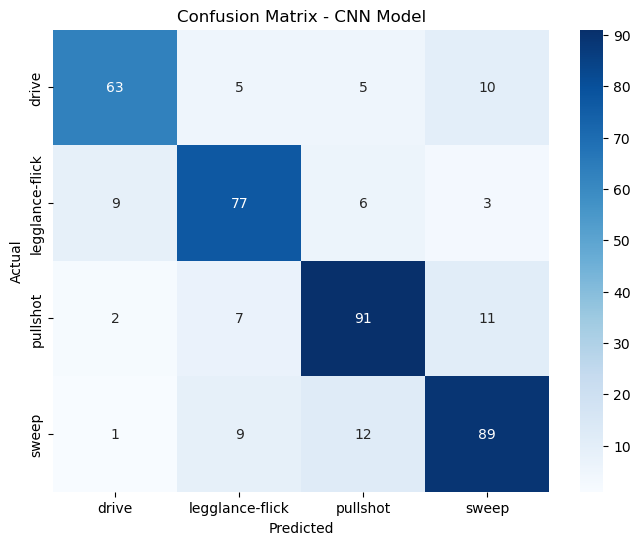

In [14]:
loss, accuracy = model1.evaluate(X_test, y_test)

y_pred_probs = model1.predict(X_test)

# Convert predictions and true labels from one-hot to integer
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Decode labels
labels = le.classes_

# Confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Classification report
print("🧾 Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=labels))

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - CNN Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Epoch 1/60
40/40 [==============================] - 2s 21ms/step - loss: 1.8205 - accuracy: 0.3205 - val_loss: 1.3352 - val_accuracy: 0.3812
Epoch 2/60
40/40 [==============================] - 1s 15ms/step - loss: 1.3924 - accuracy: 0.3934 - val_loss: 1.2140 - val_accuracy: 0.4594
Epoch 3/60
40/40 [==============================] - 1s 15ms/step - loss: 1.2029 - accuracy: 0.4835 - val_loss: 1.0252 - val_accuracy: 0.5656
Epoch 4/60
40/40 [==============================] - 1s 14ms/step - loss: 1.0329 - accuracy: 0.5313 - val_loss: 0.9846 - val_accuracy: 0.5000
Epoch 5/60
40/40 [==============================] - 1s 16ms/step - loss: 0.9034 - accuracy: 0.5948 - val_loss: 0.9384 - val_accuracy: 0.6250
Epoch 6/60
40/40 [==============================] - 1s 15ms/step - loss: 0.8380 - accuracy: 0.6262 - val_loss: 0.9346 - val_accuracy: 0.6313
Epoch 7/60
40/40 [==============================] - 1s 16ms/step - loss: 0.7630 - accuracy: 0.6450 - val_loss: 0.9717 - val_accuracy: 0.6062
Epoch 8/60
40

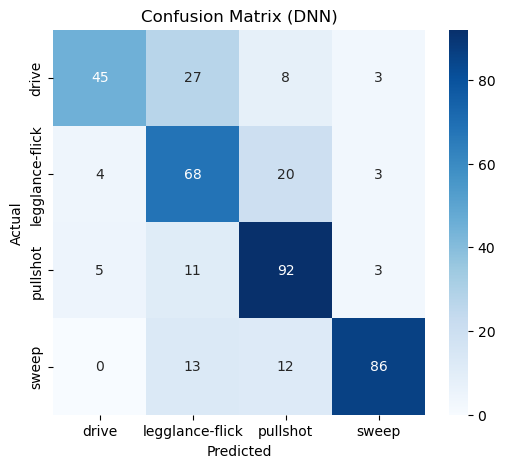


📊 Classification Report:
                 precision    recall  f1-score   support

          drive       0.83      0.54      0.66        83
legglance-flick       0.57      0.72      0.64        95
       pullshot       0.70      0.83      0.76       111
          sweep       0.91      0.77      0.83       111

       accuracy                           0.73       400
      macro avg       0.75      0.72      0.72       400
   weighted avg       0.75      0.73      0.73       400



In [17]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Flatten the image input
X = np.array(X).reshape(-1, 64*64)  # from (num_samples, 64, 64, 1) → (num_samples, 4096)

# Step 2: Encode the labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = to_categorical(y_encoded)

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Step 4: Build the DNN model
model2 = Sequential([
    Dense(512, activation='relu', input_shape=(64*64,)),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(4, activation='softmax')  # For 4-class classification
])

model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Step 5: Train the model
model2.fit(X_train, y_train, epochs=60, validation_split=0.2)

# Step 6: Evaluate the model
loss, accuracy = model2.evaluate(X_test, y_test)

# Step 7: Confusion Matrix and Classification Report
y_pred = model2.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix (DNN)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report
print("\n Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=le.classes_))


In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Set image dimensions and dataset path
IMG_SIZE = (100, 100)  
DATASET_PATH = "processed_images"  # Folder containing subfolders for each class

# Initialize lists to store image data and labels
images = []
labels = []

# Loop over each subfolder (each class)
for class_name in os.listdir(DATASET_PATH):
    class_path = os.path.join(DATASET_PATH, class_name)
    if os.path.isdir(class_path):
        # Loop through images in the subfolder
        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            # Load the image as RGB even if it is originally grayscale
            img = load_img(img_path, target_size=IMG_SIZE, color_mode='rgb')
            img_array = img_to_array(img) / 255.0  # Normalize the image
            images.append(img_array)
            labels.append(class_name)

# Convert lists to NumPy arrays
X = np.array(images)
y = np.array(labels)

# Encode string labels into numbers then convert to one-hot encoding
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_categorical = to_categorical(y_encoded)



In [2]:

# Split data into training and testing sets (stratified split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)

In [3]:
# Define data augmentation for training
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# For validation/testing, we simply rescale (images are already normalized)
test_datagen = ImageDataGenerator()

# Create generators from the arrays
train_generator = train_datagen.flow(X_train, y_train, batch_size=32)
test_generator = test_datagen.flow(X_test, y_test, batch_size=32, shuffle=False)

In [4]:
base_model = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

# Freeze the base model layers so that they are not updated during training
for layer in base_model.layers:
    layer.trainable = False

# Add custom classification layers on top of the base model
x = GlobalAveragePooling2D()(base_model.output)
x = Dense(1024, activation="relu")(x)
# Final output layer 
output = Dense(4, activation="softmax")(x)


In [5]:
# Construct the final model
model = Model(inputs=base_model.input, outputs=output)


In [6]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=["accuracy"])


In [7]:
EPOCHS = 40
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=EPOCHS, batch_size=32)

Epoch 1/40


50/50 [==============================] - 42s 828ms/step - loss: 1.3395 - accuracy: 0.3515 - val_loss: 1.2674 - val_accuracy: 0.5275
Epoch 2/40
50/50 [==============================] - 41s 814ms/step - loss: 1.2062 - accuracy: 0.5645 - val_loss: 1.1908 - val_accuracy: 0.5000
Epoch 3/40
50/50 [==============================] - 41s 825ms/step - loss: 1.1106 - accuracy: 0.6084 - val_loss: 1.1065 - val_accuracy: 0.6175
Epoch 4/40
50/50 [==============================] - 43s 863ms/step - loss: 1.0328 - accuracy: 0.6579 - val_loss: 1.0480 - val_accuracy: 0.6350
Epoch 5/40
50/50 [==============================] - 43s 863ms/step - loss: 0.9706 - accuracy: 0.6836 - val_loss: 1.0010 - val_accuracy: 0.6050
Epoch 6/40
50/50 [==============================] - 44s 879ms/step - loss: 0.9215 - accuracy: 0.6992 - val_loss: 0.9488 - val_accuracy: 0.6925
Epoch 7/40
50/50 [==============================] - 46s 925ms/step - loss: 0.8735 - accuracy: 0.7124 - val_loss: 0.9297 - val_accuracy: 0.65

13/13 [==============================] - 9s 646ms/step - loss: 0.5564 - accuracy: 0.7900
Test Accuracy: 0.7900
13/13 [==============================] - 9s 646ms/step


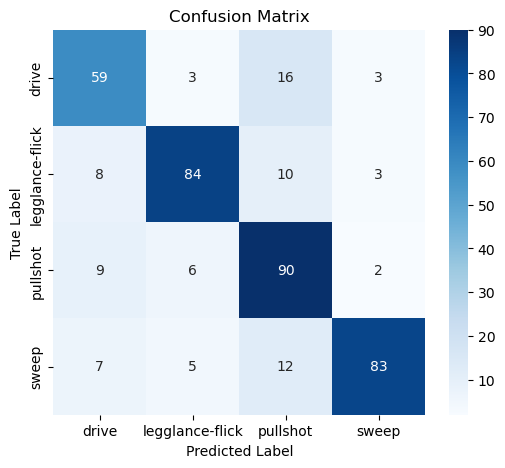

In [8]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

# Make predictions on the test set and convert to label indices
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

# Compute the confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()



In [9]:
# Print detailed classification report
print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=label_encoder.classes_))


Classification Report:
                  precision    recall  f1-score   support

          drive       0.71      0.73      0.72        81
legglance-flick       0.86      0.80      0.83       105
       pullshot       0.70      0.84      0.77       107
          sweep       0.91      0.78      0.84       107

       accuracy                           0.79       400
      macro avg       0.80      0.79      0.79       400
   weighted avg       0.80      0.79      0.79       400



In [18]:
model1.save("C:/models/model1.h5")
model2.save("C:/models/model2.h5")
model.save("C:/models/model.h5")

C:\Users\priya\anaconda3\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


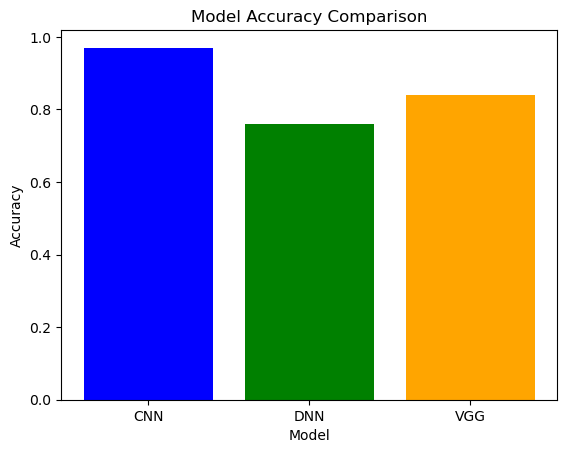

In [1]:
import matplotlib.pyplot as plt

# Model names and corresponding accuracy
models = ['CNN', 'DNN', 'VGG']
accuracy = [0.97, 0.76, 0.84]

# Create bar graph
plt.bar(models, accuracy, color=['blue', 'green', 'orange'])

# Add labels and title
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')

# Show the graph
plt.show()
